# 02 Baseline models: ridge regression and a masked multi-output network

**Question.** How closely can the 24 magnetic measurements reproduce the 16 shape parameters of the institute's reference reconstruction (position of the magnetic axis, the lower X point, two strike points and the limiter point, elongation, three triangularities, the plasma current and the limited flag) on randomly chosen whole discharges that the model did not train on, and how much does a neural network gain over a linear model? The plasma outline is not estimated. These results are for the baseline network; the model we ship is evaluated in notebook 09.

Protocol (fixed for the whole project): 5-fold GroupKFold by discharge, a loss that is masked where a target does not
exist, errors in physical units (mm, kA) and relative to the spread of the target (nRMSE = RMSE / std).
The network is the shared `ipp1_common.fit_mlp` (256-256-128, SiLU, AdamW, one-cycle schedule, 60 epochs), the linear
model is `ridge` with alpha 1. Both are trained in this notebook.

Runtime: about 1 minute (41 s measured, 2 CPU threads); needs only the raw data (`equil_data.csv`); optional `out/ipp1-baseline.json` for the comparison in section 2 (`analysis/ipp1_baseline.py`, 1 min).

In [1]:
import os, sys, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# The data live next to the repository (never inside it): HACKATHON_HOME, else the parent folder of the repository.
here = Path.cwd().resolve()
repo = next((p for p in [here, *here.parents] if (p / "analysis" / "ipp1_common.py").exists()), None)
if repo is None:
    raise SystemExit("Run from inside the repository")
os.environ.setdefault("HACKATHON_HOME", str(repo.parent))
sys.path.insert(0, str(repo / "analysis"))
import torch
torch.set_num_threads(2)
import ipp1_common as C

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
print("raw data folder found:", C.DATA.exists(), "| results folder found:", C.OUT.exists())

raw data folder found: True | results folder found: True


## 1. Folds

In [2]:
df, X, Y, G, M = C.load()
J = {t: i for i, t in enumerate(C.TARGETS)}
folds = C.group_folds(X, Y, G, 5)
lim = Y[:, J["is_limited"]] > 0.5
KEY = {}
rows = []
for k, (tr, te) in enumerate(folds):
    assert not set(G[tr]) & set(G[te]), "a discharge appears in both train and test"
    rows.append(dict(fold=k + 1, train_discharges=len(set(G[tr])), test_discharges=len(set(G[te])), train_rows=len(tr), test_rows=len(te), test_limited_share=lim[te].mean()))
print(pd.DataFrame(rows).set_index("fold").round(3).to_string())
print("no discharge is shared between the train and the test part of any fold")

      train_discharges  test_discharges  train_rows  test_rows  test_limited_share
fold                                                                              
1                  119               30       34381       8591               0.430
2                  119               30       34398       8574               0.415
3                  120               29       34415       8557               0.496
4                  119               30       34311       8661               0.423
5                  119               30       34383       8589               0.448
no discharge is shared between the train and the test part of any fold


## 2. Train ridge and the network on every fold

The out-of-fold predictions (each row is predicted by a model that never saw its discharge) are kept in memory for the
plots below.

In [3]:
t0 = time.time()
ridge_res, mlp_res = [], []
P_ridge = np.full(Y.shape, np.nan, dtype=np.float32)
P_mlp = np.full(Y.shape, np.nan, dtype=np.float32)
fold_of = np.zeros(len(X), dtype=int)
for k, (tr, te) in enumerate(folds):
    ridge_pred = C.fit_ridge(X[tr], Y[tr], M[tr])(X[te])
    predict, net, _ = C.fit_mlp(X[tr], Y[tr], M[tr], epochs=60, seed=k)
    P_ridge[te], P_mlp[te], fold_of[te] = ridge_pred, predict(X[te]), k
    ridge_res.append(C.score(P_ridge[te], Y[te], M[te]))
    mlp_res.append(C.score(P_mlp[te], Y[te], M[te]))
    print(f"fold {k + 1}/5 done, {time.time() - t0:.0f} s", flush=True)
KEY["training_seconds_5_folds_both_models"] = round(time.time() - t0, 1)
KEY["network_parameters"] = int(sum(p.numel() for p in net.parameters()))


def mean_over_folds(res, t, key):
    return float(np.mean([f[t][key] for f in res]))


def std_over_folds(res, t, key):
    return float(np.std([f[t][key] for f in res]))

fold 1/5 done, 6 s


fold 2/5 done, 12 s


fold 3/5 done, 18 s


fold 4/5 done, 23 s


fold 5/5 done, 29 s


## 3. Results table (mean over the 5 folds)

`spread` is the standard deviation of the target in the same unit; `MLP MAE / spread` says how large the typical error
is compared with how much the quantity moves.

In [4]:
rows = []
for t in C.TARGETS:
    scale, unit = C.UNIT[t]
    j = J[t]
    spread = float(Y[M[:, j], j].std() * scale)
    rows.append(dict(target=t, unit=unit or "-", spread=spread,
                     ridge_MAE=mean_over_folds(ridge_res, t, "mae"), MLP_MAE=mean_over_folds(mlp_res, t, "mae"),
                     MLP_MAE_fold_std=std_over_folds(mlp_res, t, "mae"),
                     MLP_MAE_over_spread=mean_over_folds(mlp_res, t, "mae") / spread,
                     ridge_R2=mean_over_folds(ridge_res, t, "r2"), MLP_R2=mean_over_folds(mlp_res, t, "r2"),
                     ridge_nRMSE=mean_over_folds(ridge_res, t, "nrmse"), MLP_nRMSE=mean_over_folds(mlp_res, t, "nrmse")))
tab = pd.DataFrame(rows).set_index("target")
print(tab.round(4).to_string())
KEY["table"] = {t: {k: (round(float(v), 5) if k != "unit" else v) for k, v in r.items()} for t, r in tab.to_dict("index").items()}
KEY["is_limited_accuracy"] = {"ridge": mean_over_folds(ridge_res, "is_limited", "accuracy"), "mlp": mean_over_folds(mlp_res, "is_limited", "accuracy")}
print()
print(f"is_limited accuracy: ridge {KEY['is_limited_accuracy']['ridge']:.4f}, MLP {KEY['is_limited_accuracy']['mlp']:.4f}")
KEY["mean_nrmse_without_limiter_targets"] = {
    m: float(np.mean([mean_over_folds(res, t, "nrmse") for t in C.TARGETS if t not in ("R_limiter", "Z_limiter", "is_limited")]))
    for m, res in (("ridge", ridge_res), ("mlp", mlp_res))}
print("mean nRMSE over the 13 targets without limiter point and is_limited:", {k: round(v, 4) for k, v in KEY["mean_nrmse_without_limiter_targets"].items()})

                    unit    spread  ridge_MAE  MLP_MAE  MLP_MAE_fold_std  MLP_MAE_over_spread  ridge_R2  MLP_R2  ridge_nRMSE  MLP_nRMSE
target                                                                                                                                 
plasma_current        kA  114.1844     0.0346   1.4883            0.4215               0.0130    1.0000  0.9992       0.0004     0.0271
R_mag_axis            mm    8.0216     2.3988   0.3772            0.1162               0.0470    0.5273  0.9766       0.6819     0.1394
Z_mag_axis            mm   13.7411     2.6613   0.3915            0.0788               0.0285    0.7740  0.9844       0.4448     0.1069
elongation             -    0.2706     0.0920   0.0057            0.0013               0.0210    0.5966  0.9982       0.6248     0.0408
triangularity          -    0.1194     0.0410   0.0028            0.0006               0.0238    0.5744  0.9974       0.6439     0.0483
triangularity_upper    -    0.0749     0.0251   

### Does it agree with the earlier baseline script?

`analysis/ipp1_baseline.py` wrote `out/ipp1-baseline.json` with the same protocol (it used 4 torch threads). Small
differences are expected because training is not bit-for-bit identical across thread counts.

In [5]:
saved_path = C.OUT / "ipp1-baseline.json"
if saved_path.exists():
    saved = json.load(open(saved_path))["average"]["mlp"]
    cmp = pd.DataFrame({"this notebook": {t: tab.loc[t, "MLP_MAE"] for t in C.TARGETS}, "saved script": {t: saved[t]["mae"] for t in C.TARGETS}})
    cmp["ratio"] = cmp["this notebook"] / cmp["saved script"]
    print(cmp.round(4).to_string())
    KEY["ratio_to_saved_baseline_min_max"] = [float(cmp.ratio.min()), float(cmp.ratio.max())]
else:
    print("saved baseline not found; comparison skipped")

                     this notebook  saved script  ratio
plasma_current              1.4883        1.4883    1.0
R_mag_axis                  0.3772        0.3772    1.0
Z_mag_axis                  0.3915        0.3915    1.0
elongation                  0.0057        0.0057    1.0
triangularity               0.0028        0.0028    1.0
triangularity_upper         0.0030        0.0030    1.0
triangularity_lower         0.0037        0.0037    1.0
R_x_point                   0.2024        0.2024    1.0
Z_x_point                   0.1952        0.1952    1.0
R_strike_point_1            0.2646        0.2646    1.0
Z_strike_point_1            0.1307        0.1307    1.0
R_strike_point_2            0.2281        0.2281    1.0
Z_strike_point_2            0.0552        0.0552    1.0
R_limiter                  10.7303       10.7303    1.0
Z_limiter                  22.1927       22.1927    1.0
is_limited                  0.0203        0.0203    1.0


## 4. Figures: relative error per target, and estimate against reference

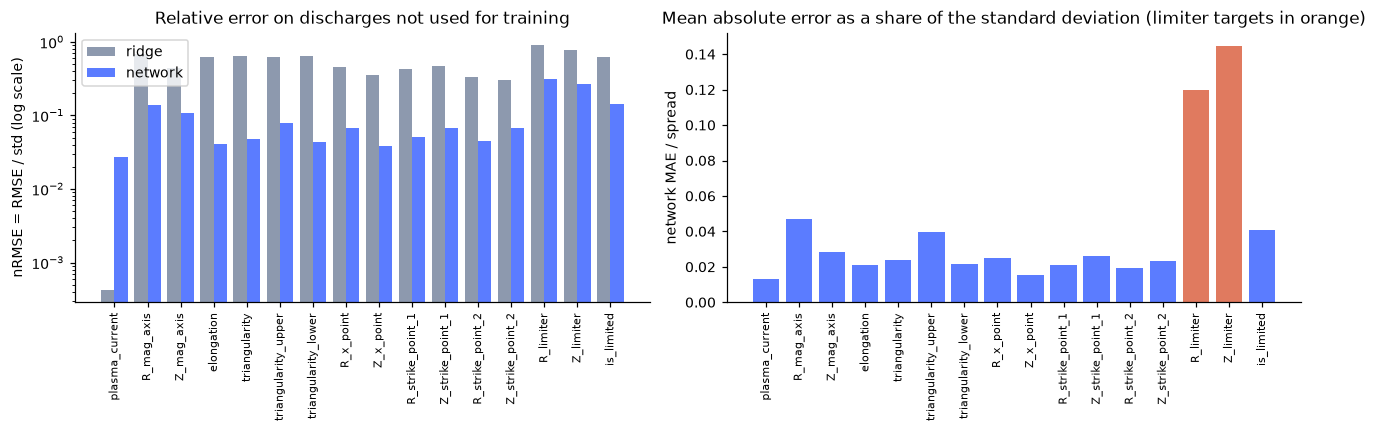

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
xs = np.arange(len(C.TARGETS))
ax[0].bar(xs - 0.2, tab.ridge_nRMSE, 0.4, label="ridge", color="#8d99ae")
ax[0].bar(xs + 0.2, tab.MLP_nRMSE, 0.4, label="network", color="#5b7cff")
ax[0].set_yscale("log"); ax[0].set_xticks(xs); ax[0].set_xticklabels(C.TARGETS, rotation=90, fontsize=7)
ax[0].set_ylabel("nRMSE = RMSE / std (log scale)"); ax[0].legend(); ax[0].set_title("Relative error on discharges not used for training")
ax[1].bar(xs, tab.MLP_MAE_over_spread, color=["#e07a5f" if t in ("R_limiter", "Z_limiter") else "#5b7cff" for t in C.TARGETS])
ax[1].set_xticks(xs); ax[1].set_xticklabels(C.TARGETS, rotation=90, fontsize=7)
ax[1].set_ylabel("network MAE / spread"); ax[1].set_title("Mean absolute error as a share of the standard deviation (limiter targets in orange)")
fig.tight_layout(); plt.show()

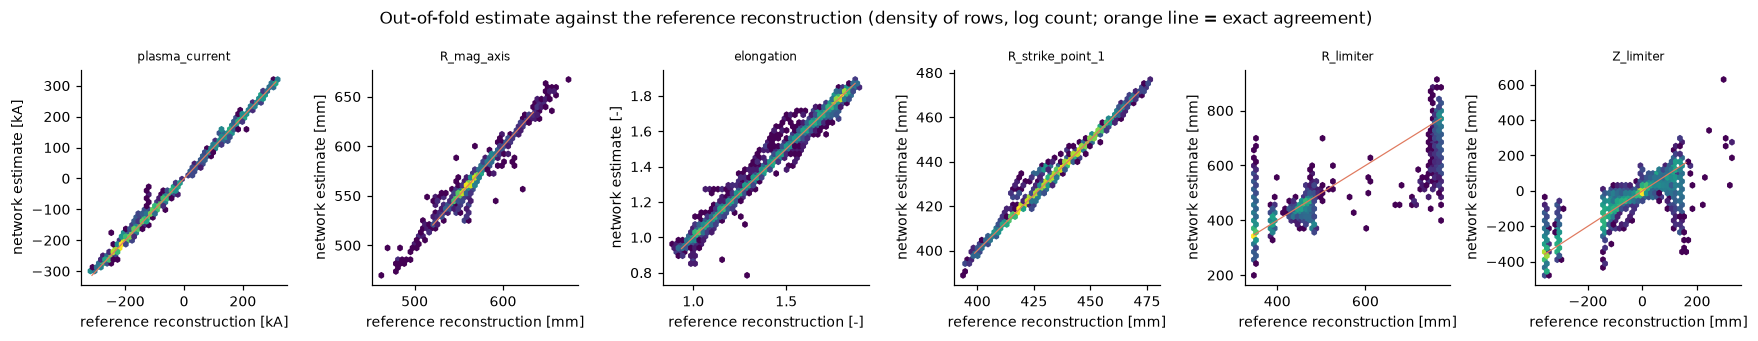

In [7]:
show = ["plasma_current", "R_mag_axis", "elongation", "R_strike_point_1", "R_limiter", "Z_limiter"]
fig, ax = plt.subplots(1, len(show), figsize=(16, 3.1))
for a, t in zip(ax, show):
    j = J[t]; scale, unit = C.UNIT[t]; k = M[:, j]
    a.hexbin(Y[k, j] * scale, P_mlp[k, j] * scale, gridsize=45, bins="log", cmap="viridis", mincnt=1)
    lo, hi = np.percentile(Y[k, j] * scale, [0.1, 99.9])
    a.plot([lo, hi], [lo, hi], color="#e07a5f", lw=0.8)
    a.set_title(t, fontsize=8); a.set_xlabel(f"reference reconstruction [{unit or '-'}]"); a.set_ylabel(f"network estimate [{unit or '-'}]")
fig.suptitle("Out-of-fold estimate against the reference reconstruction (density of rows, log count; orange line = exact agreement)")
fig.tight_layout(); plt.show()

## 5. Where the network is weakest: the limiter point

`R_limiter` and `Z_limiter` exist only when the plasma touches the limiter. We look at them by configuration and by
whether `is_limited` itself was classified correctly.

is_limited misclassified in 0.0074 of all out-of-fold rows
               unit  MAE_limited_rows  MAE_divertor_rows
target                                                  
plasma_current   kA            2.0130             1.0709
R_mag_axis       mm            0.5534             0.2373
Z_mag_axis       mm            0.5161             0.2925
elongation        -            0.0082             0.0037
triangularity     -            0.0042             0.0018
          unit   spread    MAE_all  MAE_median    MAE_p95  MAE_if_class_right  MAE_if_class_wrong  rows_class_wrong
target                                                                                                             
R_limiter   mm   89.597  10.806000       2.641  49.036999              10.774              14.482               163
Z_limiter   mm  153.271  22.250999       9.317  90.849998              22.288              18.014               163


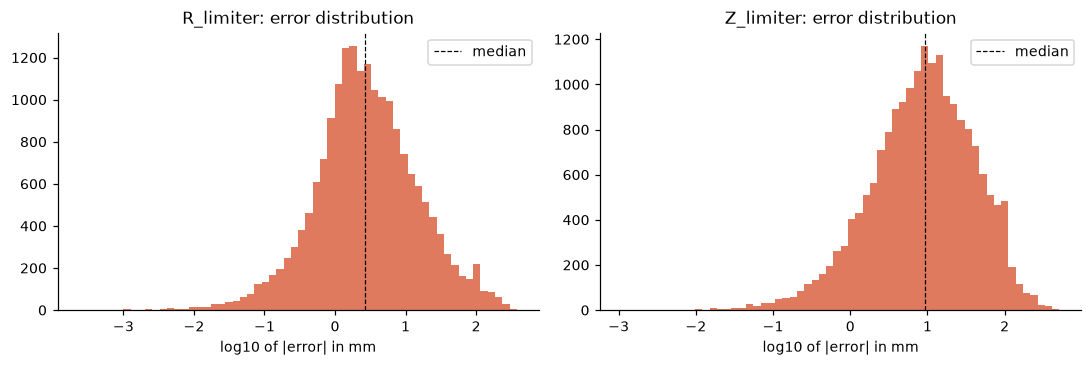

tail of the radial and vertical axis error (median, 99th percentile; mm): {'R_mag_axis': [0.153, 3.74], 'Z_mag_axis': [0.18, 3.55]}


In [8]:
pooled = C.score(P_mlp, Y, M)
KEY["pooled_oof_mae"] = {t: round(pooled[t]["mae"], 5) for t in C.TARGETS}
pred_lim = P_mlp[:, J["is_limited"]] > 0.5
KEY["misclassified_share"] = float((pred_lim != lim).mean())
print(f"is_limited misclassified in {KEY['misclassified_share']:.4f} of all out-of-fold rows")
rows = []
for t in ["plasma_current", "R_mag_axis", "Z_mag_axis", "elongation", "triangularity"]:
    j = J[t]; scale, unit = C.UNIT[t]
    e = np.abs(P_mlp[:, j] - Y[:, j]) * scale
    rows.append(dict(target=t, unit=unit or "-", MAE_limited_rows=np.nanmean(e[lim]), MAE_divertor_rows=np.nanmean(e[~lim])))
by_config = pd.DataFrame(rows).set_index("target")
print(by_config.round(4).to_string())
KEY["mae_by_configuration"] = {t: [round(float(r.MAE_limited_rows), 5), round(float(r.MAE_divertor_rows), 5)] for t, r in by_config.iterrows()}

rows = []
for t in ("R_limiter", "Z_limiter"):
    j = J[t]; scale, unit = C.UNIT[t]
    k = M[:, j]
    e = np.abs(P_mlp[:, j] - Y[:, j]) * scale
    ok = k & pred_lim
    bad = k & ~pred_lim
    rows.append(dict(target=t, unit=unit, spread=float(Y[k, j].std() * scale), MAE_all=e[k].mean(), MAE_median=np.median(e[k]),
                     MAE_p95=np.percentile(e[k], 95), MAE_if_class_right=e[ok].mean(), MAE_if_class_wrong=e[bad].mean() if bad.any() else np.nan,
                     rows_class_wrong=int(bad.sum())))
lt = pd.DataFrame(rows).set_index("target")
print(lt.round(3).to_string())
KEY["limiter"] = {t: {k: (round(float(v), 4)) for k, v in r.items() if k != "unit"} for t, r in lt.to_dict("index").items()}

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for a, t in zip(ax, ("R_limiter", "Z_limiter")):
    j = J[t]; scale, unit = C.UNIT[t]; k = M[:, j]
    e = np.abs(P_mlp[k, j] - Y[k, j]) * scale
    a.hist(np.log10(e + 1e-6), bins=60, color="#e07a5f")
    a.axvline(np.log10(np.median(e)), color="k", lw=0.8, ls="--", label="median")
    a.set_xlabel(f"log10 of |error| in {unit}"); a.set_title(f"{t}: error distribution"); a.legend()
fig.tight_layout(); plt.show()
print("tail of the radial and vertical axis error (median, 99th percentile; mm):", {t: [round(float(np.nanmedian(np.abs(P_mlp[:, J[t]] - Y[:, J[t]]) * C.UNIT[t][0])), 3), round(float(np.nanpercentile(np.abs(P_mlp[:, J[t]] - Y[:, J[t]]) * C.UNIT[t][0], 99)), 2)] for t in ("R_mag_axis", "Z_mag_axis")})

## 6. Uneven distribution of shapes (REQ-007): is the error larger for rare shapes?

We cut the elongation range into 10 equal-width bins. Common shapes fill a few bins; rare shapes sit in sparse bins.
The error per bin is the out-of-fold MAE of the network for `elongation`, `R_mag_axis` and `plasma_current`.

     elongation_from   rows  MAE_elongation  MAE_R_mag_axis  MAE_plasma_current
bin                                                                            
1             0.8865    259          0.0136          3.0487              2.2262
2             0.9872   3614          0.0064          0.8866              2.4224
3             1.0879   2150          0.0077          0.6698              1.9965
4             1.1887   1831          0.0061          0.5973              1.7909
5             1.2894   1670          0.0056          0.3238              1.4790
6             1.3901   1915          0.0078          0.2769              1.4028
7             1.4908   1346          0.0105          0.3547              1.8335
8             1.5915   2345          0.0115          0.4471              3.2671
9             1.6923  12704          0.0054          0.3176              1.2762
10            1.7930  15137          0.0037          0.2012              1.0257
elongation: MAE in the 3 fullest bins 0.

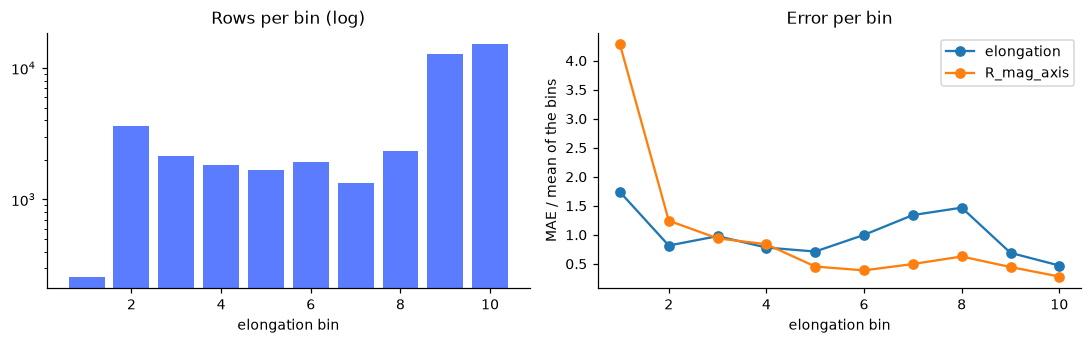

In [9]:
valid = M[:, [J["elongation"], J["R_mag_axis"], J["plasma_current"]]].all(1)  # one row lacks several targets
el = Y[valid, J["elongation"]].astype(np.float64)
Pv, Yv = P_mlp[valid], Y[valid]
edges = np.linspace(el.min(), el.max() + 1e-9, 11)
b = np.clip(np.digitize(el, edges) - 1, 0, 9)
cnt = np.bincount(b, minlength=10)
rows = []
for i in range(10):
    s = b == i
    row = dict(bin=i + 1, elongation_from=edges[i], rows=int(cnt[i]))
    for t in ("elongation", "R_mag_axis", "plasma_current"):
        j = J[t]; scale, unit = C.UNIT[t]
        row[f"MAE_{t}"] = np.abs(Pv[s, j] - Yv[s, j]).mean() * scale if s.sum() else np.nan
    rows.append(row)
dens = pd.DataFrame(rows).set_index("bin")
print(dens.round(4).to_string())
common = cnt >= np.sort(cnt)[-3]
sparse = (cnt > 0) & (cnt < 0.02 * len(el))
KEY["density_bins"] = {"rows_per_bin": cnt.tolist()}
for t in ("elongation", "R_mag_axis", "plasma_current"):
    j = J[t]; scale, unit = C.UNIT[t]
    e = np.abs(Pv[:, j] - Yv[:, j]) * scale
    in_common = common[b]
    in_sparse = sparse[b]
    KEY["density_bins"][t] = {"MAE_in_3_fullest_bins": float(e[in_common].mean()), "MAE_in_sparse_bins_under_2pct_of_rows": float(e[in_sparse].mean()) if in_sparse.any() else None,
                              "rows_in_sparse_bins": int(in_sparse.sum())}
    print(f"{t}: MAE in the 3 fullest bins {e[in_common].mean():.4g}, in bins with under 2 % of the rows {e[in_sparse].mean():.4g} ({in_sparse.sum()} rows) [{unit or '-'}]")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].bar(range(1, 11), cnt, color="#5b7cff"); ax[0].set_yscale("log"); ax[0].set_xlabel("elongation bin"); ax[0].set_title("Rows per bin (log)")
ax[1].plot(range(1, 11), dens.MAE_elongation / dens.MAE_elongation.mean(), marker="o", label="elongation")
ax[1].plot(range(1, 11), dens.MAE_R_mag_axis / dens.MAE_R_mag_axis.mean(), marker="o", label="R_mag_axis")
ax[1].set_xlabel("elongation bin"); ax[1].set_ylabel("MAE / mean of the bins"); ax[1].legend(); ax[1].set_title("Error per bin")
fig.tight_layout(); plt.show()

## Conclusions

- **Setup.** 5 folds by whole discharges (about 119 to 120 training and 29 to 30 test discharges each, checked: no discharge is on both sides), masked loss, network with 107,152 parameters, 60 epochs. Training both models on all folds took 35 s with 2 threads in the stored run (172 s in the first run, on a busy machine). The results equal the earlier script `ipp1_baseline.py` (ratio of the MAE values from 1.0000 to 1.0000 on the owner's machine with the same number of threads; another CPU gives small differences, and without `out/ipp1-baseline.json` this comparison is skipped).
- **The network agrees closely with the reference reconstruction on discharges it did not train on** (random group folds; the labels are the institute's reconstruction, not an independent measurement of the plasma). Mean absolute difference: `R_mag_axis` 0.38 mm, `Z_mag_axis` 0.39 mm, `R_x_point` 0.20 mm, `R_strike_point_1` 0.26 mm, `R_strike_point_2` 0.23 mm, elongation 0.0057, plasma current 1.49 kA. `is_limited` agrees in 99.26 % of the rows. The mean absolute error is 1.3 % to 4.7 % of the standard deviation of each target (limiter point excluded); the nRMSE, which weights large errors more, is 2.7 % to 13.9 %. The mean hides a tail: for `R_mag_axis` the median is 0.15 mm, 99 % of the rows are below 3.7 mm and the worst row is 64 mm (`results/ipp1-distribution.md`), mostly at the two ends of a discharge. The discharge numbers appear to follow time (not confirmed with the organizers); trained on the 60 lowest and tested on the 59 highest development discharges the radial axis error is 1.23 mm instead of 0.45 mm on the same discharges (`results/ipp1-final.md`; part of this is the smaller training set; see notebook 09).
- **The network beats ridge on almost everything.** Mean nRMSE over the 13 targets without the limiter point and `is_limited` is 0.0633 for the network and 0.4629 for ridge (7.3 times worse), and `is_limited` accuracy is 91.2 % for ridge. For example `R_mag_axis` has an MAE of 2.40 mm with ridge against 0.38 mm.
- **One exception: the plasma current is linear in the measurements.** Ridge reaches an MAE of 0.035 kA (R squared 1.0000) for the plasma current, while the network has 1.49 kA, about 43 times worse. For this one output the linear model should be used (alone or as an input to the network). This is expected from Ampere's law: the 16 IPR coils integrate the magnetic field around the vessel. The agreement of 0.035 kA on a spread of 114 kA (0.03 %) suggests that the reference current was derived from the same signals and was not measured independently (our inference, not confirmed).
- **The limiter point is the weak spot.** `R_limiter` has an MAE of 10.7 mm (12 % of its spread of 90 mm) and `Z_limiter` 22.2 mm (14 % of 153 mm). The error has a heavy tail: the median `R_limiter` error is 2.6 mm but the 95th percentile is 49 mm. Wrong `is_limited` classification (0.74 % of rows, 163 rows with a limiter point) is not the main cause: pooled over all out-of-fold rows, the `R_limiter` MAE is 10.8 mm when the class is right and 14.5 mm when it is wrong. For `Z_limiter` a wrong class is not worse (18.0 against 22.3 mm).
- **Limited plasma is harder than divertor plasma.** The `R_mag_axis` MAE is 0.55 mm in limited rows and 0.24 mm in divertor rows; for the plasma current 2.01 and 1.07 kA; for elongation 0.0082 and 0.0037.
- **Rare shapes have larger errors (REQ-007).** In the 3 fullest elongation bins the `R_mag_axis` MAE is 0.33 mm; in the sparse bins (under 2 % of the rows, 259 rows, the least elongated plasmas) it is 3.05 mm, and for elongation itself 0.0047 against 0.0136. The headline averages are dominated by the common shapes. Limited plasma carries 91.9 % of the squared `R_mag_axis` error with 44.2 % of the rows, the 16 discharges with positive current sign 77.8 % with 7.4 % of the rows, and the last 2 % of a discharge 26.9 % with 2.2 % of the rows (notebook 07). This was measured, not corrected: no reweighting and no stratified folds were tried. The sparsest elongation bin holds values below 1 (0.89 to 0.99), which are unusual for a tokamak plasma; the organizers' definition is not recorded here.
- **Caveat.** One training seed per fold; the standard deviation over folds is given in the results table (for example `R_mag_axis` 0.38 plus or minus 0.12 mm).

*The conclusions above were typed from the outputs of the stored run and differ slightly after a rerun.*

**Answer.** On randomly chosen discharges that the model did not train on, the network differs from the institute's reference reconstruction by a mean of 0.38 mm (radial) and 0.39 mm (vertical) on the axis position (median 0.15 mm, 99 % of the rows below 3.7 mm), and it is 7.3 times better than ridge on the summary error; only the plasma current is better with the linear model (0.035 against 1.49 kA). The weak spot is the limiter point (10.7 mm and 22.2 mm), and the error is concentrated in limited plasma, in the discharges with positive current sign and at the ends of a discharge.